Let's investigate five hypotheses.

H1 — Seasonalit: Does the delay rate vary between months?

H2 — Geography: Do deliveries between different states take longer?

H3 — Distance: Is geographical distance associated with delivery time?

H4 — Complexity: Do orders with more items or vendors take longer?

H5 — Promised deadline: Is the duration of the estimated deadline associated with the probability of delay?

# Data preparation

Importing libraries and loading datasets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

DATA_PATH = Path("../data/raw")

orders = pd.read_csv(
    DATA_PATH / "olist_orders_dataset.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

order_items = pd.read_csv(
    DATA_PATH / "olist_order_items_dataset.csv"
)

customers = pd.read_csv(
    DATA_PATH / "olist_customers_dataset.csv"
)

sellers = pd.read_csv(
    DATA_PATH / "olist_sellers_dataset.csv"
)

sns.set_theme(style="whitegrid")

print(f"Orders: {orders.shape}")
print(f"Order items: {order_items.shape}")
print(f"Customers: {customers.shape}")
print(f"Sellers: {sellers.shape}")

Orders: (99441, 8)
Order items: (112650, 7)
Customers: (99441, 5)
Sellers: (3095, 4)


Defining the population for analysis.

In [ ]:
required_dates = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

delivered_orders = orders.loc[
    (orders["order_status"] == "delivered")
    & orders[required_dates].notna().all(axis=1)
].copy()

delivered_orders["delivery_time_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivered_orders = delivered_orders.loc[
    delivered_orders["delivery_time_days"] >= 0
].copy()

delivered_orders["is_delayed"] = (
    delivered_orders["order_delivered_customer_date"].dt.normalize()
    > delivered_orders["order_estimated_delivery_date"].dt.normalize()
).astype(int)

print("Orders:", len(delivered_orders))
print("Delay rate:", delivered_orders["is_delayed"].mean())

Orders: 96470
Delay rate: 0.06773090079817559


Creating temporal variables

In [5]:
delivered_orders["purchase_month"] = (
    delivered_orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

delivered_orders["purchase_weekday"] = (
    delivered_orders["order_purchase_timestamp"]
    .dt.day_of_week
)

delivered_orders["purchase_hour"] = (
    delivered_orders["order_purchase_timestamp"]
    .dt.hour
)

delivered_orders["purchase_year"] = (
    delivered_orders["order_purchase_timestamp"]
    .dt.year
)

# H1 - Temporal analysis

Hypotheses 1 — Does the delay rate vary between months?

In [6]:
monthly_analysis = (
    delivered_orders
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "count"),
        delayed_orders=("is_delayed", "sum"),
        delay_rate=("is_delayed", "mean"),
        avg_delivery_days=("delivery_time_days", "mean")
    )
    .reset_index()
)

monthly_analysis["purchase_month"] = (
    monthly_analysis["purchase_month"].astype(str)
)

monthly_analysis

,purchase_month,total_orders,delayed_orders,delay_rate,avg_delivery_days
0,2016-09,1,1,1.000000,54.813194
1,2016-10,265,2,0.007547,19.600559
2,2016-12,1,0,0.000000,4.693021
3,2017-01,750,22,0.029333,12.647044
4,2017-02,1653,49,0.029643,13.168825
5,2017-03,2546,116,0.045562,12.951184
6,2017-04,2303,151,0.065567,14.917913
7,2017-05,3545,106,0.029901,11.322363
8,2017-06,3135,95,0.030303,12.011573
9,2017-07,3872,108,0.027893,11.592732


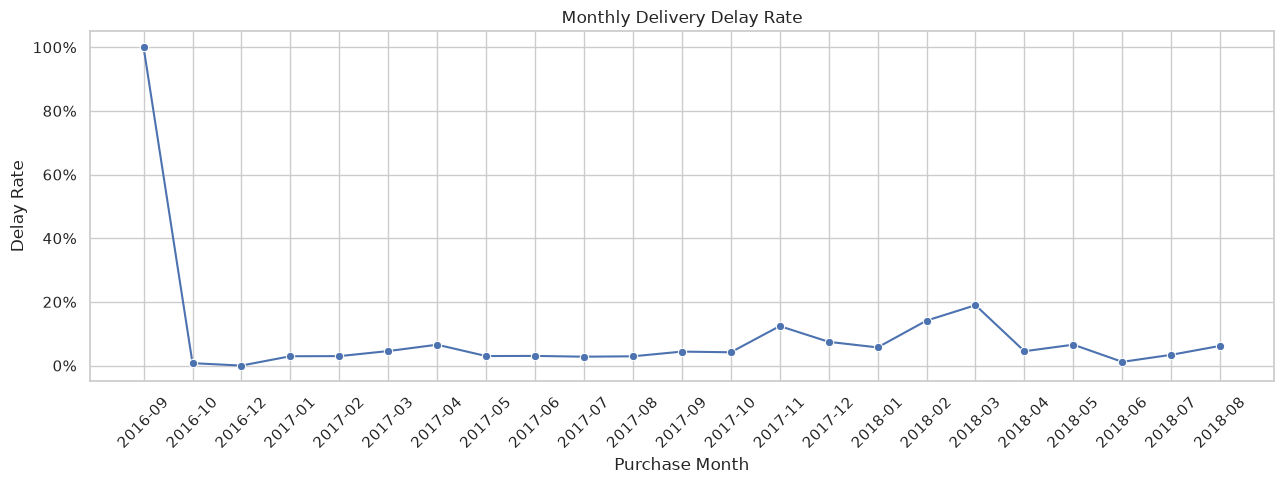

In [7]:
fig, ax = plt.subplots(figsize=(13, 5))

sns.lineplot(
    data=monthly_analysis,
    x="purchase_month",
    y="delay_rate",
    marker="o",
    ax=ax
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

ax.set_title("Monthly Delivery Delay Rate")
ax.set_xlabel("Purchase Month")
ax.set_ylabel("Delay Rate")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

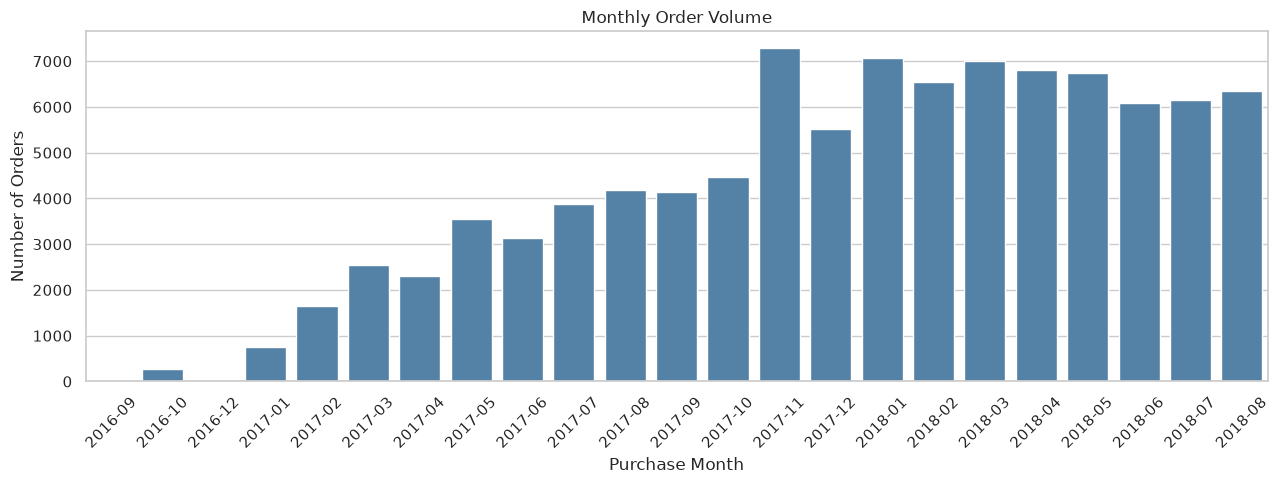

In [8]:
fig, ax = plt.subplots(figsize=(13, 5))

sns.barplot(
    data=monthly_analysis,
    x="purchase_month",
    y="total_orders",
    color="steelblue",
    ax=ax
)

ax.set_title("Monthly Order Volume")
ax.set_xlabel("Purchase Month")
ax.set_ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Delays by day of the week

In [9]:
weekday_analysis = (
    delivered_orders
    .groupby("purchase_weekday")
    .agg(
        total_orders=("order_id", "count"),
        delay_rate=("is_delayed", "mean"),
        avg_delivery_days=("delivery_time_days", "mean")
    )
    .reset_index()
)

weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_analysis["weekday_name"] = (
    weekday_analysis["purchase_weekday"]
    .map(weekday_names)
)

weekday_analysis

,purchase_weekday,total_orders,delay_rate,avg_delivery_days,weekday_name
0,0,15701,0.074390,11.998224,Monday
1,1,15502,0.070507,12.075733,Tuesday
2,2,15074,0.065676,12.442995,Wednesday
3,3,14322,0.063050,12.740592,Thursday
4,4,13684,0.070155,13.573355,Friday
5,5,10555,0.065940,13.362731,Saturday
6,6,11632,0.062242,11.957633,Sunday


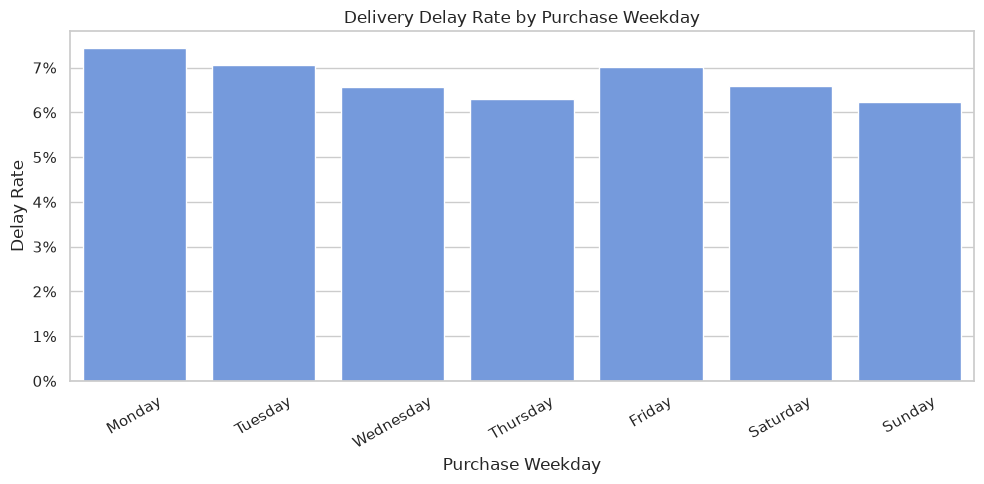

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=weekday_analysis,
    x="weekday_name",
    y="delay_rate",
    color="cornflowerblue",
    ax=ax
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

ax.set_title("Delivery Delay Rate by Purchase Weekday")
ax.set_xlabel("Purchase Weekday")
ax.set_ylabel("Delay Rate")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# H2 - Geographic analysis

Hypotheses 2: Do deliveries between different states have longer delivery times than deliveries within the same state?

Integrating customer data

In [12]:
orders_geo = delivered_orders.merge(
    customers[
        [
            "customer_id",
            "customer_state",
            "customer_city"
        ]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Before:", len(delivered_orders))
print("After:", len(orders_geo))

assert len(orders_geo) == len(delivered_orders)
assert orders_geo["order_id"].is_unique

Before: 96470
After: 96470


Group vendors by order

In [13]:
order_sellers = (
    order_items[
        ["order_id", "seller_id"]
    ]
    .drop_duplicates()
    .merge(
        sellers[
            ["seller_id", "seller_state"]
        ],
        on="seller_id",
        how="left",
        validate="many_to_one"
    )
)

seller_aggregation = (
    order_sellers
    .groupby("order_id")
    .agg(
        seller_count=("seller_id", "nunique"),
        seller_state_count=("seller_state", "nunique")
    )
    .reset_index()
)

In [14]:
seller_customer = order_sellers.merge(
    orders_geo[
        ["order_id", "customer_state"]
    ],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

seller_customer["same_state"] = (
    seller_customer["seller_state"]
    == seller_customer["customer_state"]
)

same_state_aggregation = (
    seller_customer
    .groupby("order_id")
    .agg(
        all_sellers_same_state=("same_state", "all")
    )
    .reset_index()
)

orders_geo = (
    orders_geo
    .merge(
        seller_aggregation,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        same_state_aggregation,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

Compare delivery times

In [15]:
geo_analysis = (
    orders_geo
    .dropna(subset=["all_sellers_same_state"])
    .groupby("all_sellers_same_state")
    .agg(
        total_orders=("order_id", "count"),
        avg_delivery_days=("delivery_time_days", "mean"),
        median_delivery_days=("delivery_time_days", "median"),
        delay_rate=("is_delayed", "mean")
    )
    .reset_index()
)

geo_analysis["delivery_type"] = (
    geo_analysis["all_sellers_same_state"]
    .map({
        True: "Same state",
        False: "Different states"
    })
)

geo_analysis

,all_sellers_same_state,total_orders,avg_delivery_days,median_delivery_days,delay_rate,delivery_type
0,False,61895,15.133230,12.775405,0.080313,Different states
1,True,34575,7.948515,6.551181,0.045206,Same state


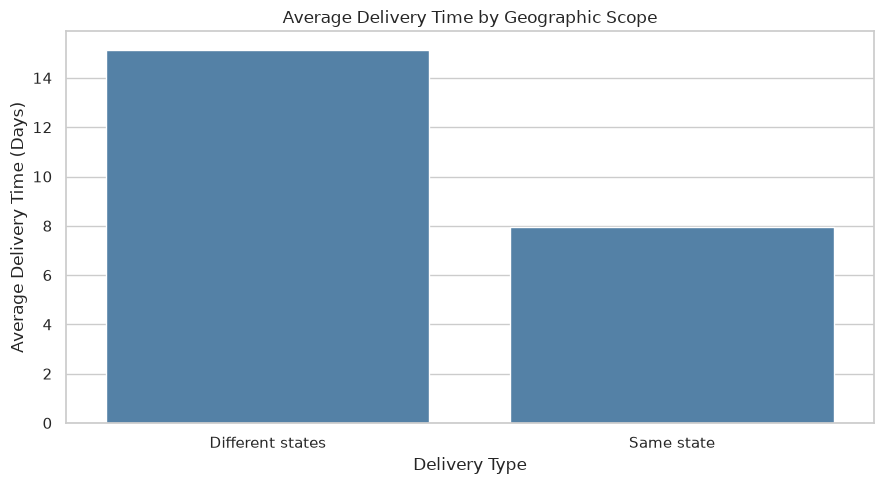

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=geo_analysis,
    x="delivery_type",
    y="avg_delivery_days",
    color="steelblue",
    ax=ax
)

ax.set_title("Average Delivery Time by Geographic Scope")
ax.set_xlabel("Delivery Type")
ax.set_ylabel("Average Delivery Time (Days)")

plt.tight_layout()
plt.show()

# H3 - Geographical distance

Hypotheses 3: The greater the distance between seller and consumer, the longer the delivery time tends to be.

Load and prepare geographic data.

In [17]:
geolocation = pd.read_csv(
    DATA_PATH / "olist_geolocation_dataset.csv"
)

geo_coordinates = (
    geolocation
    .groupby("geolocation_zip_code_prefix")
    .agg(
        latitude=("geolocation_lat", "median"),
        longitude=("geolocation_lng", "median")
    )
    .reset_index()
)

print(geo_coordinates.shape)
print(geo_coordinates.head())

(19015, 3)
   geolocation_zip_code_prefix   latitude  longitude
0                         1001 -23.550381 -46.634027
1                         1002 -23.548551 -46.635072
2                         1003 -23.548977 -46.635313
3                         1004 -23.549535 -46.634771
4                         1005 -23.549612 -46.636532


Associate coordinates with clients and vendors.

In [18]:
customer_coordinates = customers[
    ["customer_id", "customer_zip_code_prefix"]
].merge(
    geo_coordinates,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left",
    validate="many_to_one"
).rename(
    columns={
        "latitude": "customer_lat",
        "longitude": "customer_lng"
    }
)

seller_coordinates = sellers[
    ["seller_id", "seller_zip_code_prefix"]
].merge(
    geo_coordinates,
    left_on="seller_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left",
    validate="many_to_one"
).rename(
    columns={
        "latitude": "seller_lat",
        "longitude": "seller_lng"
    }
)

Implementing Haversine

In [19]:
def haversine_distance(
    lat1, lon1, lat2, lon2
):
    R = 6371.0

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    a = np.clip(a, 0, 1)

    return 2 * R * np.arcsin(np.sqrt(a))

Calculate the distances

In [20]:
order_distances = (
    order_sellers[
        ["order_id", "seller_id"]
    ]
    .merge(
        seller_coordinates[
            ["seller_id", "seller_lat", "seller_lng"]
        ],
        on="seller_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        orders_geo[
            ["order_id", "customer_id"]
        ],
        on="order_id",
        how="inner",
        validate="many_to_one"
    )
    .merge(
        customer_coordinates[
            ["customer_id", "customer_lat", "customer_lng"]
        ],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
)

order_distances["distance_km"] = haversine_distance(
    order_distances["seller_lat"],
    order_distances["seller_lng"],
    order_distances["customer_lat"],
    order_distances["customer_lng"]
)

In [ ]:
# since some orders have multiple vendors, we will calculate three statistics

distance_features = (
    order_distances
    .groupby("order_id")
    .agg(
        min_distance_km=("distance_km", "min"),
        avg_distance_km=("distance_km", "mean"),
        max_distance_km=("distance_km", "max")
    )
    .reset_index()
)

orders_geo = orders_geo.merge(
    distance_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

assert orders_geo["order_id"].is_unique

print(
    orders_geo[
        ["min_distance_km", "avg_distance_km", "max_distance_km"]
    ].describe()
)

       min_distance_km  avg_distance_km  max_distance_km
count     95994.000000     95994.000000     95994.000000
mean        599.389523       600.718191       602.052611
std         593.979088       593.877491       594.373195
min           0.000000         0.000000         0.000000
25%         182.263585       186.872620       188.635305
50%         431.939189       433.883313       435.528657
75%         796.570596       797.342084       800.188904
max        8677.859564      8677.859564      8677.859564


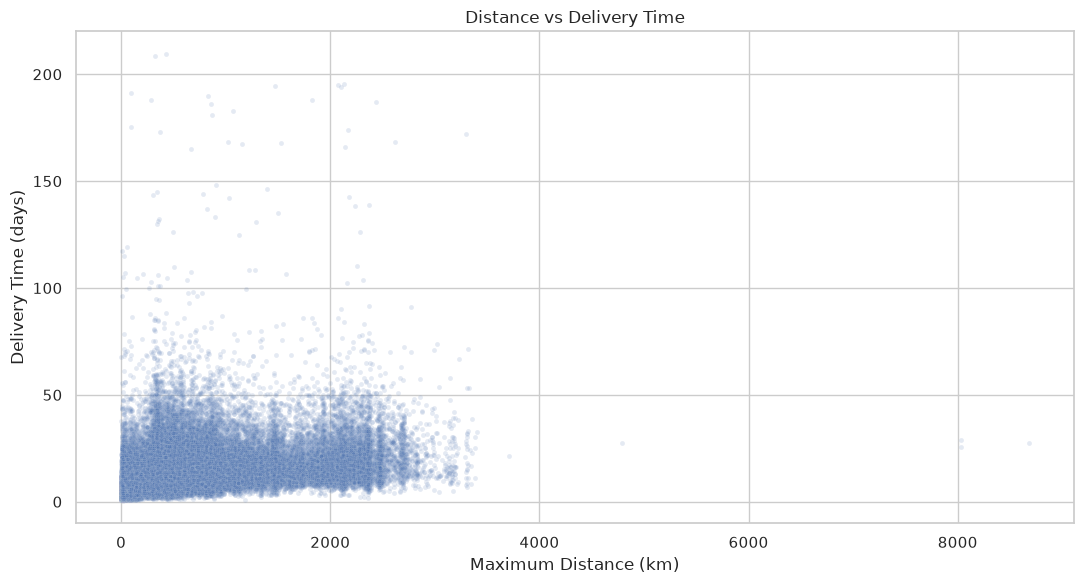

In [22]:
plot_data = orders_geo.dropna(
    subset=[
        "max_distance_km",
        "delivery_time_days"
    ]
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.scatterplot(
    data=plot_data,
    x="max_distance_km",
    y="delivery_time_days",
    alpha=0.15,
    s=12,
    ax=ax
)

ax.set_title("Distance vs Delivery Time")
ax.set_xlabel("Maximum Distance (km)")
ax.set_ylabel("Delivery Time (days)")

plt.tight_layout()
plt.show()

In [23]:
distance_bins = [0, 100, 300, 600, 1000, 2000, np.inf]

distance_labels = [
    "0–100",
    "100–300",
    "300–600",
    "600–1000",
    "1000–2000",
    "2000+"
]

plot_data = plot_data.copy()

plot_data["distance_range"] = pd.cut(
    plot_data["max_distance_km"],
    bins=distance_bins,
    labels=distance_labels,
    include_lowest=True
)

distance_analysis = (
    plot_data
    .groupby("distance_range", observed=True)
    .agg(
        total_orders=("order_id", "count"),
        avg_delivery_days=("delivery_time_days", "mean"),
        median_delivery_days=("delivery_time_days", "median"),
        delay_rate=("is_delayed", "mean")
    )
    .reset_index()
)

distance_analysis

,distance_range,total_orders,avg_delivery_days,median_delivery_days,delay_rate
0,0–100,17795,6.513355,5.090637,0.044788
1,100–300,13314,9.995171,8.196898,0.051975
2,300–600,31521,12.611910,10.314144,0.067511
3,600–1000,17972,14.690711,12.487274,0.070777
4,1000–2000,9764,17.925746,15.329653,0.094633
5,2000+,5628,21.155342,18.252639,0.120291


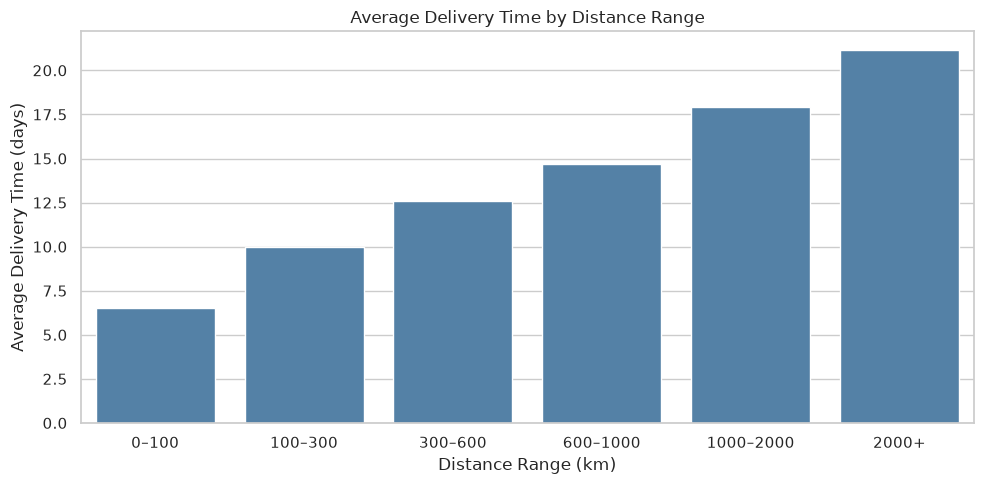

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=distance_analysis,
    x="distance_range",
    y="avg_delivery_days",
    color="steelblue",
    ax=ax
)

ax.set_title("Average Delivery Time by Distance Range")
ax.set_xlabel("Distance Range (km)")
ax.set_ylabel("Average Delivery Time (days)")

plt.tight_layout()
plt.show()

Spearman's correlation between distance and delivery time.

In [25]:
correlation = plot_data[
    ["max_distance_km", "delivery_time_days"]
].corr(method="spearman")

print(correlation)

                    max_distance_km  delivery_time_days
max_distance_km            1.000000            0.540564
delivery_time_days         0.540564            1.000000


The max distance shown was 8.677,86km

This value warrants investigation because it is very high for a straight-line distance between points in Brazilian territory.

We shouldn't automatically conclude it's an error, but we need to check for possible incorrect coordinates or points outside the expected geographic area.

In [ ]:
extreme_distances = (
    order_distances.loc[
        order_distances["distance_km"] > 4000,
        [
            "order_id",
            "seller_id",
            "customer_lat",
            "customer_lng",
            "seller_lat",
            "seller_lng",
            "distance_km"
        ]
    ]
    .sort_values("distance_km", ascending=False)
)

print("Records above 4.000 km:", len(extreme_distances))

display(extreme_distances.head(20))

Registros acima de 4.000 km: 4


,order_id,seller_id,customer_lat,customer_lng,seller_lat,seller_lng,distance_km
52848,8ad3f1d0f96992e43566c4c82c9f6c58,0417b067eeab773d2f7061a726dc477f,42.184003,-8.723762,-26.231306,-49.412569,8677.859564
29615,4d5abe7999d76d1fb6237d3677706af0,431af27f296bc6519d890aa5a05fdb11,41.146203,-8.577855,-21.258652,-47.813946,8032.929717
65827,acdbc7396e191931c263db11af241d62,431af27f296bc6519d890aa5a05fdb11,41.146203,-8.577855,-21.258652,-47.813946,8032.929717
52333,897ec6416d50126a9061626f0fc2d658,6560211a19b47992c3666cc44a7e94c0,13.001420,-23.583939,-23.652443,-46.755492,4791.606339


The minimum observed to distance value is zero.

This can occur when the customer and seller have the same postal code prefix, as we use coordinates aggregated by prefix.

Therefore, a distance of zero does not necessarily mean that the customer and seller are at the same address.

In [28]:
zero_distance = order_distances.loc[
    order_distances["distance_km"] == 0
]

print("Distances equal to zero:", len(zero_distance))

Distances equal to zero: 23


# H4 - Complexity of requests

Hypotheses 4: Do orders with more items or from different vendors result in longer delivery times?

We will use `order_items` to calculate:

- Number of items.

- Number of distinct products.

- Number of sellers.

- Total value of the products.

- Total shipping cost.

- Total weight, later if necessary.

Building the complexity features

In [30]:
order_complexity = (
    order_items
    .groupby("order_id")
    .agg(
        items_quantity=("order_item_id", "count"),
        unique_products=("product_id", "nunique"),
        sellers_quantity=("seller_id", "nunique"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum")
    )
    .reset_index()
)

print(order_complexity.describe())

       items_quantity  unique_products  sellers_quantity   total_price  \
count    98666.000000     98666.000000      98666.000000  98666.000000   
mean         1.141731         1.038098          1.013622    137.754076   
std          0.538452         0.226456          0.122297    210.645145   
min          1.000000         1.000000          1.000000      0.850000   
25%          1.000000         1.000000          1.000000     45.900000   
50%          1.000000         1.000000          1.000000     86.900000   
75%          1.000000         1.000000          1.000000    149.900000   
max         21.000000         8.000000          5.000000  13440.000000   

       total_freight  
count   98666.000000  
mean       22.823562  
std        21.650909  
min         0.000000  
25%        13.850000  
50%        17.170000  
75%        24.040000  
max      1794.960000  


Integrate the features

In [31]:
orders_complexity = orders_geo.merge(
    order_complexity,
    on="order_id",
    how="left",
    validate="one_to_one"
)

assert len(orders_complexity) == len(orders_geo)
assert orders_complexity["order_id"].is_unique

print(
    orders_complexity[
        [
            "items_quantity",
            "unique_products",
            "sellers_quantity",
            "total_price",
            "total_freight"
        ]
    ].isna().sum()
)

items_quantity      0
unique_products     0
sellers_quantity    0
total_price         0
total_freight       0
dtype: int64


Quantity of items versus delivery time

In [32]:
items_analysis = (
    orders_complexity
    .groupby("items_quantity")
    .agg(
        total_orders=("order_id", "count"),
        avg_delivery_days=("delivery_time_days", "mean"),
        median_delivery_days=("delivery_time_days", "median"),
        delay_rate=("is_delayed", "mean")
    )
    .reset_index()
)

display(items_analysis)

,items_quantity,total_orders,avg_delivery_days,median_delivery_days,delay_rate
0,1,86835,12.639136,10.261215,0.069373
1,2,7392,11.826892,9.874253,0.053707
2,3,1306,11.632372,9.859780,0.049005
3,4,495,12.233637,10.008380,0.046465
4,5,193,12.038005,10.299977,0.046632
5,6,191,11.893492,10.292859,0.083770
6,7,22,11.670133,10.330446,0.000000
7,8,8,13.477030,13.701105,0.000000
8,9,3,9.431424,9.466285,0.000000
9,10,8,10.027878,9.239578,0.000000


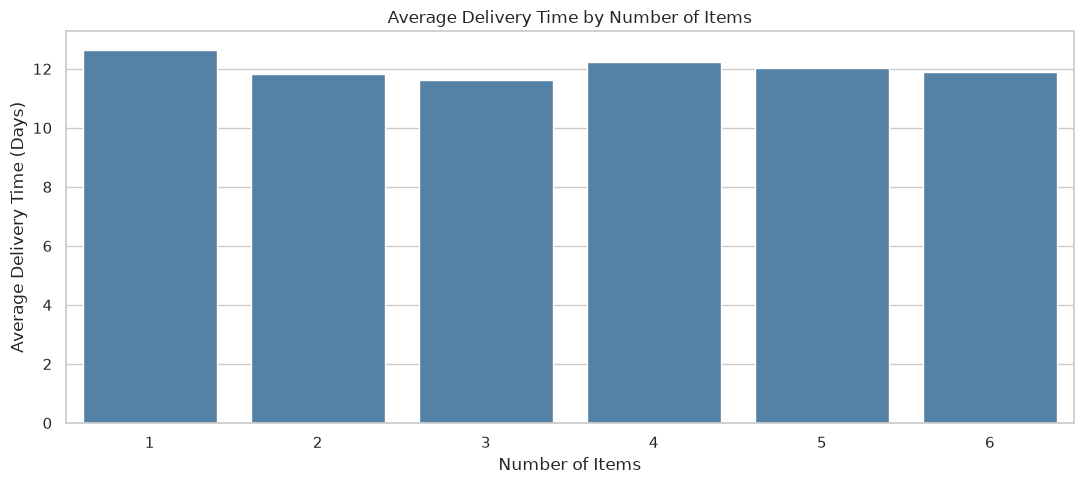

In [33]:
# most frequent groups

items_plot = items_analysis.loc[
    items_analysis["total_orders"] >= 100
]

fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    data=items_plot,
    x="items_quantity",
    y="avg_delivery_days",
    color="steelblue",
    ax=ax
)

ax.set_title("Average Delivery Time by Number of Items")
ax.set_xlabel("Number of Items")
ax.set_ylabel("Average Delivery Time (Days)")

plt.tight_layout()
plt.show()

Number of salespeople versus delays

In [34]:
sellers_analysis = (
    orders_complexity
    .groupby("sellers_quantity")
    .agg(
        total_orders=("order_id", "count"),
        avg_delivery_days=("delivery_time_days", "mean"),
        delay_rate=("is_delayed", "mean")
    )
    .reset_index()
)

display(sellers_analysis)

,sellers_quantity,total_orders,avg_delivery_days,delay_rate
0,1,95195,12.604035,0.068501
1,2,1216,9.174063,0.010691
2,3,54,8.124547,0.000000
3,4,3,9.743233,0.000000
4,5,2,13.231285,0.000000


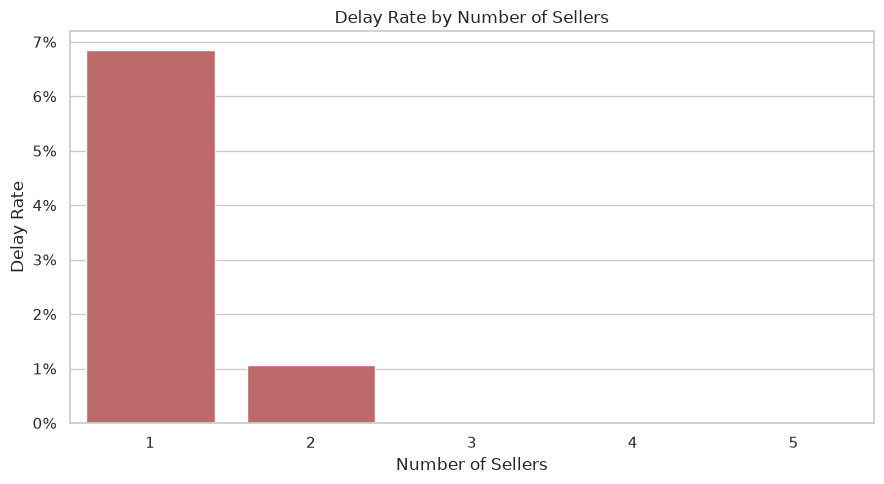

In [35]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=sellers_analysis,
    x="sellers_quantity",
    y="delay_rate",
    color="indianred",
    ax=ax
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

ax.set_title("Delay Rate by Number of Sellers")
ax.set_xlabel("Number of Sellers")
ax.set_ylabel("Delay Rate")

plt.tight_layout()
plt.show()

Assess correlations

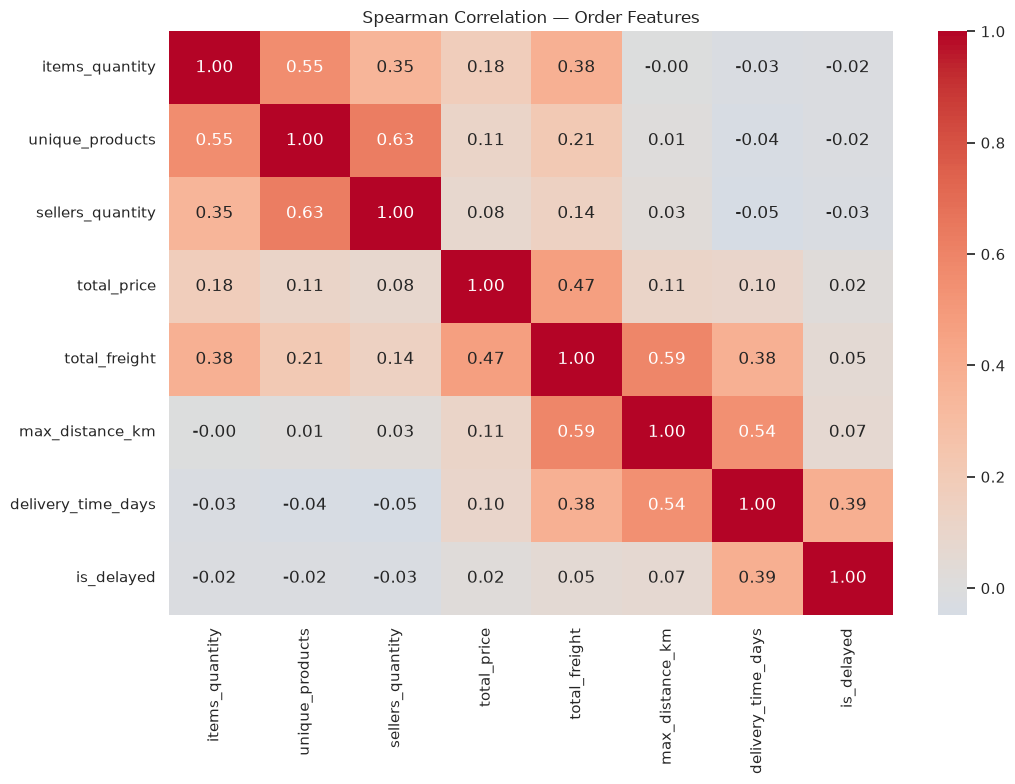

In [36]:
complexity_features = [
    "items_quantity",
    "unique_products",
    "sellers_quantity",
    "total_price",
    "total_freight",
    "max_distance_km",
    "delivery_time_days",
    "is_delayed"
]

correlation_matrix = (
    orders_complexity[complexity_features]
    .corr(method="spearman")
)

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax
)

ax.set_title("Spearman Correlation — Order Features")

plt.tight_layout()
plt.show()

# H5 - Promised deadline and delay

Hypotheses 5: Is the promised deadline length associated with the probability of delay?

Let's distinguish three variables: `promised_days`, `delivery_time_days`, `is_delayed`

Construct the promised deadline variable.

In [38]:
orders_complexity["promised_days"] = (
    orders_complexity["order_estimated_delivery_date"]
    - orders_complexity["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print(
    orders_complexity["promised_days"].describe()
)

print(
    "Negative deadlines:",
    (orders_complexity["promised_days"] < 0).sum()
)

count    96470.000000
mean        23.736343
std          8.761052
min          2.008009
25%         18.329905
50%         23.230880
75%         28.407795
max        155.135463
Name: promised_days, dtype: float64
Negative deadlines: 0


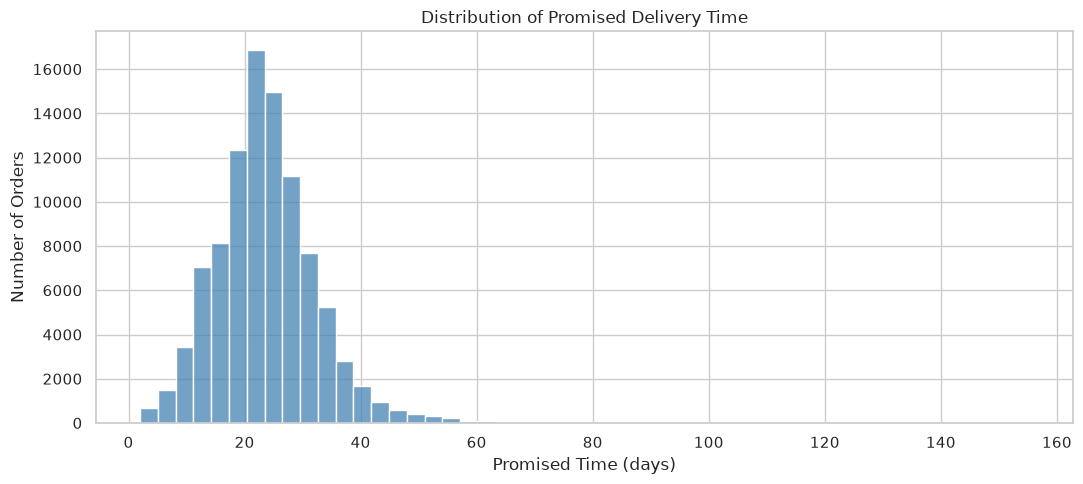

In [39]:
fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    data=orders_complexity,
    x="promised_days",
    bins=50,
    color="steelblue",
    ax=ax
)

ax.set_title("Distribution of Promised Delivery Time")
ax.set_xlabel("Promised Time (days)")
ax.set_ylabel("Number of Orders")

plt.tight_layout()
plt.show()

Comparing promised delivery time and actual time.

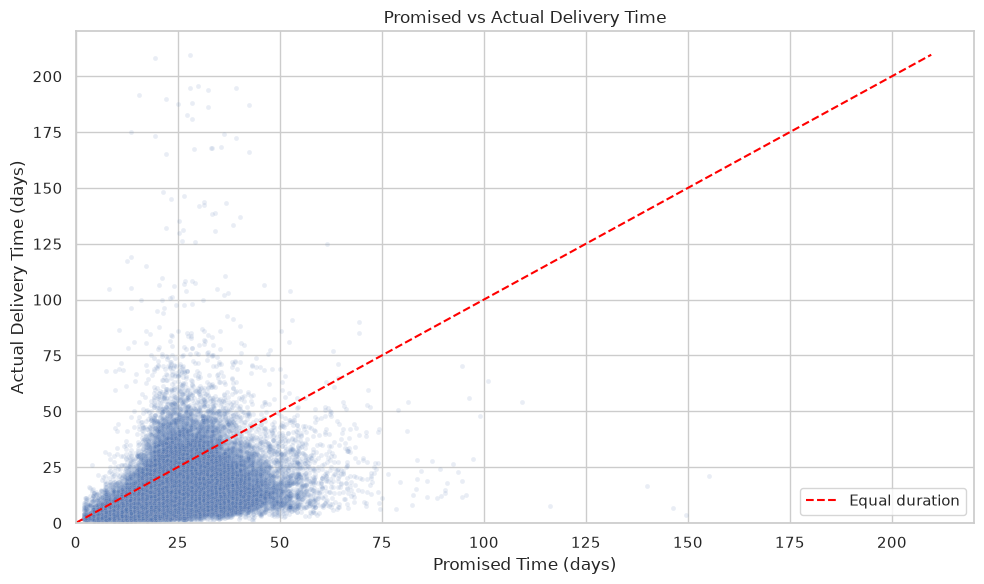

In [40]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=orders_complexity,
    x="promised_days",
    y="delivery_time_days",
    alpha=0.12,
    s=12,
    ax=ax
)

limit = max(
    orders_complexity["promised_days"].max(),
    orders_complexity["delivery_time_days"].max()
)

ax.plot(
    [0, limit],
    [0, limit],
    linestyle="--",
    color="red",
    label="Equal duration"
)

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

ax.set_title("Promised vs Actual Delivery Time")
ax.set_xlabel("Promised Time (days)")
ax.set_ylabel("Actual Delivery Time (days)")
ax.legend()

plt.tight_layout()
plt.show()

Promised timeframe ranges

In [41]:
promise_bins = [-np.inf, 7, 14, 21, 30, 45, np.inf]

promise_labels = [
    "Up to 7",
    "7–14",
    "14–21",
    "21–30",
    "30–45",
    "45+"
]

orders_complexity["promise_range"] = pd.cut(
    orders_complexity["promised_days"],
    bins=promise_bins,
    labels=promise_labels
)

promise_analysis = (
    orders_complexity
    .groupby("promise_range", observed=True)
    .agg(
        total_orders=("order_id", "count"),
        avg_delivery_days=("delivery_time_days", "mean"),
        delay_rate=("is_delayed", "mean")
    )
    .reset_index()
)

display(promise_analysis)

,promise_range,total_orders,avg_delivery_days,delay_rate
0,Up to 7,1260,4.312861,0.169048
1,7–14,10742,5.786841,0.049525
2,14–21,23304,9.813569,0.074236
3,21–30,41292,13.772361,0.074445
4,30–45,18004,17.157178,0.052877
5,45+,1868,20.135536,0.017666


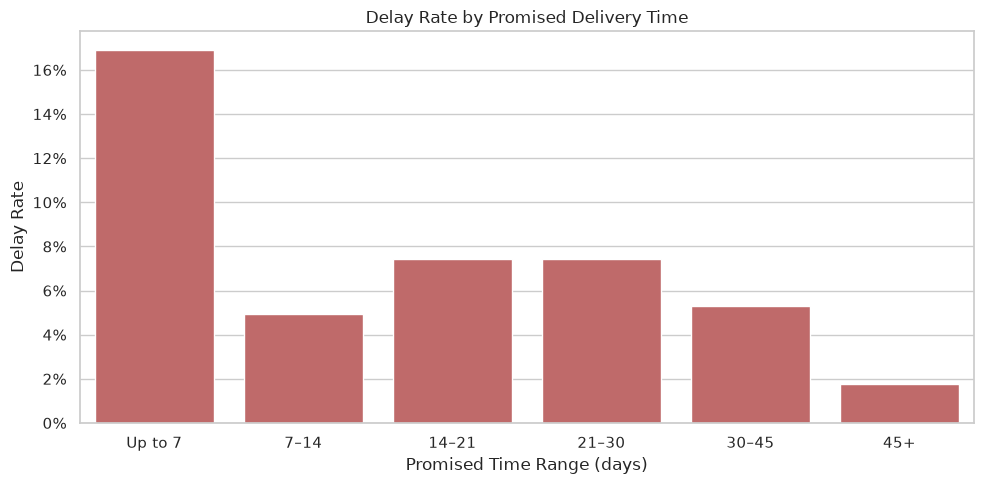

In [42]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=promise_analysis,
    x="promise_range",
    y="delay_rate",
    color="indianred",
    ax=ax
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

ax.set_title("Delay Rate by Promised Delivery Time")
ax.set_xlabel("Promised Time Range (days)")
ax.set_ylabel("Delay Rate")

plt.tight_layout()
plt.show()

# Exploratory Data Analysis — Final Conclusions

## Main findings

The exploratory analysis was conducted on 96,470 delivered orders with valid timestamps. The observed delivery delay rate was approximately 6.77%.

**H1 — Seasonality:** Delivery delay rates vary over time. Some months present substantially higher rates, suggesting temporal variation that should be considered during model development.

**H2 — Geography:** Interstate deliveries take longer on average than deliveries within the same state. They also present higher delay rates.

**H3 — Distance:** Geographic distance shows a positive Spearman correlation of approximately 0.541 with delivery time. Distance is therefore a relevant candidate predictor.

**H4 — Order complexity:** The number of items and sellers does not exhibit a consistently increasing relationship with delivery time. These variables should be evaluated jointly with geographic and temporal characteristics.

**H5 — Promised delivery time:** The relationship between promised delivery duration and delay probability is non-monotonic. Short promised deadlines show particularly high delay rates, while very long deadlines show lower rates.

## Data quality considerations

- Some geographic coordinates appear inconsistent with the expected Brazilian territory.
- Approximately 0.49% of analyzed orders lack a calculated geographic distance.
- Orders with multiple sellers require aggregation to preserve one record per order.
- Extreme geographic distances require validation before model training.
- Small groups can produce unstable estimates.

## Modeling implications

The initial modeling dataset should include temporal, geographic, order complexity, and promised delivery features.

The prediction targets are:

- **Regression:** actual delivery time in days.
- **Classification:** whether the order was delivered after the promised calendar date.

Only information available at prediction time should be included as model features.

A chronological train/validation/test split should be preferred to a random split to better simulate future predictions.